In [95]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings('ignore')

In [96]:
df = pd.read_csv('insurance.csv')
df 


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# EDA



In [97]:
df.shape


(1338, 7)

In [98]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [99]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [100]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [101]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [102]:
numeric_columns=['age','bmi','children','charges']

# DATA VISUALIZATION

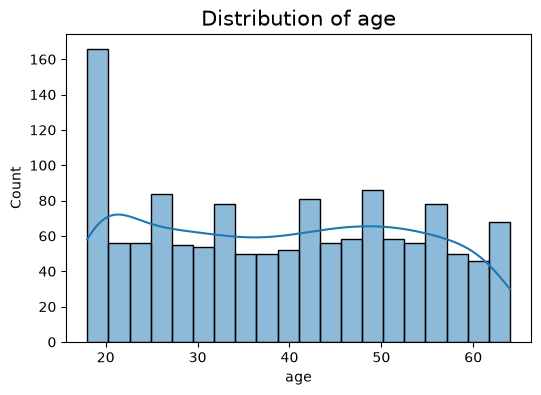

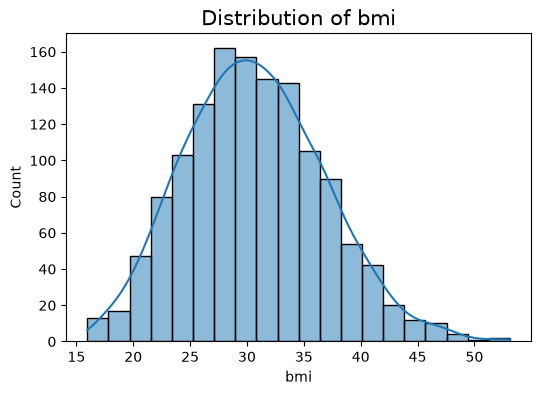

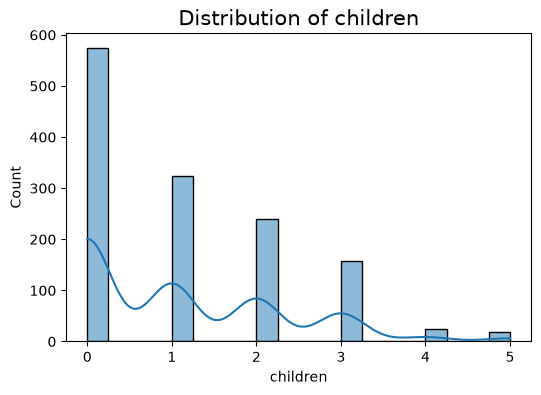

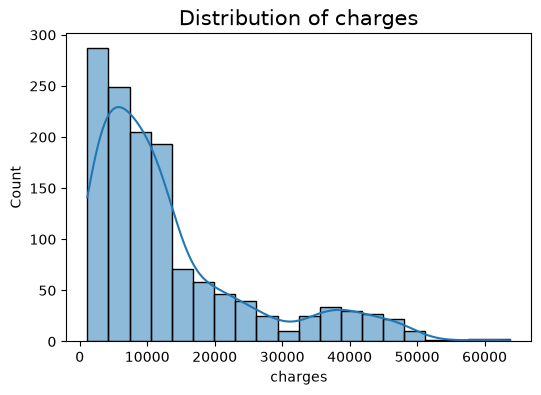

In [103]:
for cols in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[cols],kde=True, bins=20)
    plt.title(f'Distribution of {cols}',fontsize=15)
    plt.show()

<Axes: xlabel='children', ylabel='count'>

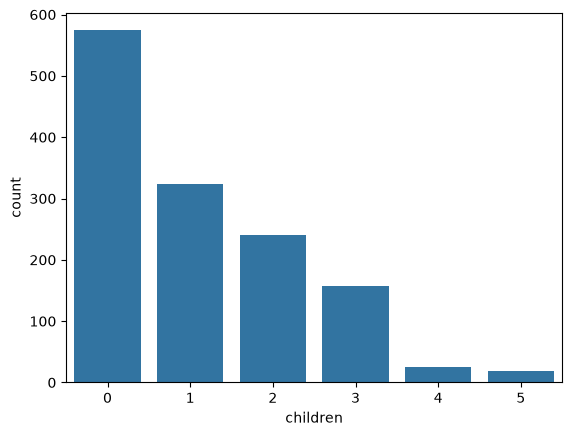

In [104]:
sns.countplot(x=df['children'])

<Axes: xlabel='sex', ylabel='count'>

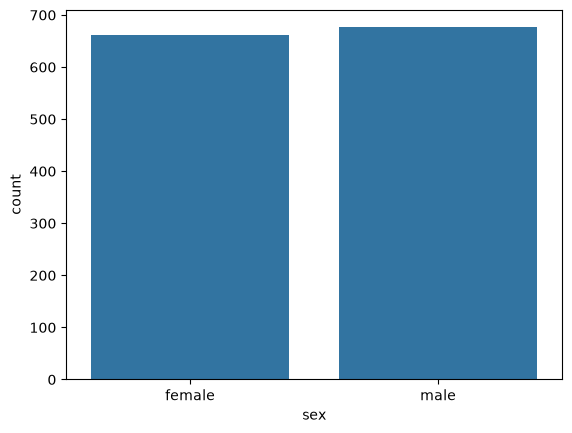

In [105]:
sns.countplot(x='sex',data=df)


<Axes: xlabel='smoker', ylabel='count'>

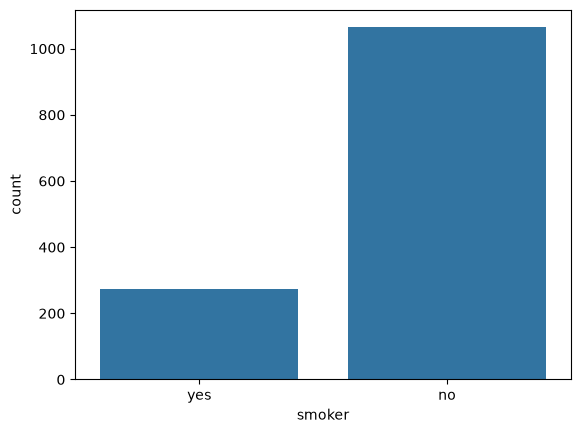

In [106]:
sns.countplot(x=df['smoker'])

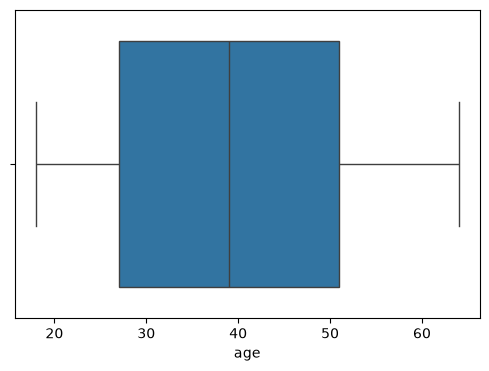

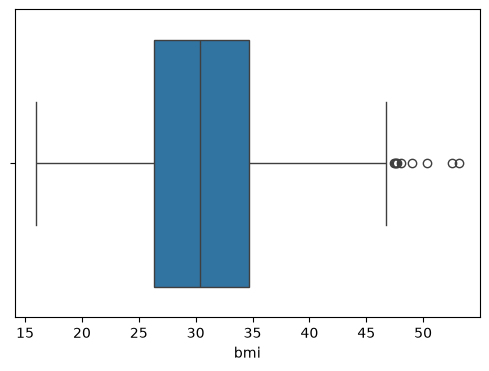

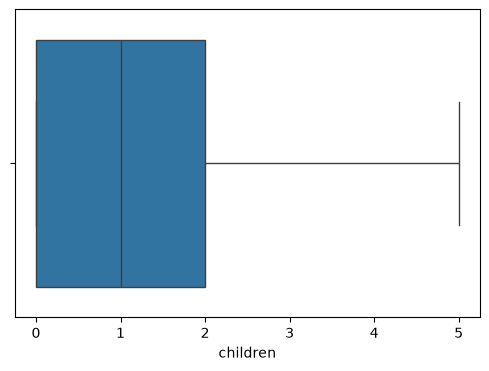

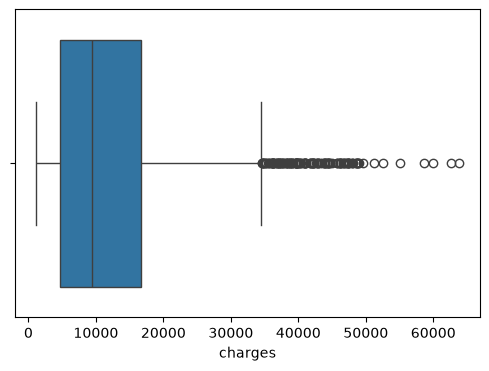

In [107]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])

<Axes: >

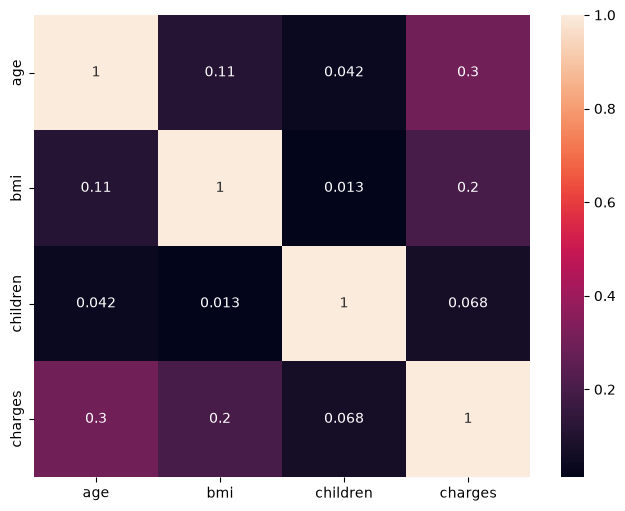

In [108]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

# DATA CLEANING AND PRE-PROCESSING

In [134]:
cleaned_df=df.copy()

In [135]:
cleaned_df.drop_duplicates(inplace=True)

In [136]:
cleaned_df.shape

(1337, 7)

In [137]:
cleaned_df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [138]:
cleaned_df.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

# label encoding for sex and smoker

In [139]:
cleaned_df['sex']=cleaned_df['sex'].map({"male":0,"female":1})

In [140]:
cleaned_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [141]:
cleaned_df['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [142]:
cleaned_df['smoker']=cleaned_df['smoker'].map({"yes":1,"no":0})

In [143]:
cleaned_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [144]:
cleaned_df.rename(columns={
  "sex": "is_female",
    "smoker": "is_smoker"
 },inplace=True)

In [146]:
cleaned_df.head()


,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [147]:
cleaned_df['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

# One hot encoding for region


In [148]:
cleaned_df=pd.get_dummies(cleaned_df,columns=['region'],drop_first=True)
cleaned_df.head().astype(int)

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,1
1,18,0,33,1,0,1725,0,1,0
2,28,0,33,3,0,4449,0,1,0
3,33,0,22,0,0,21984,1,0,0
4,32,0,28,0,0,3866,1,0,0


# FEATURE ENGINEERING AND EXTRACTION

<Axes: xlabel='bmi', ylabel='Count'>

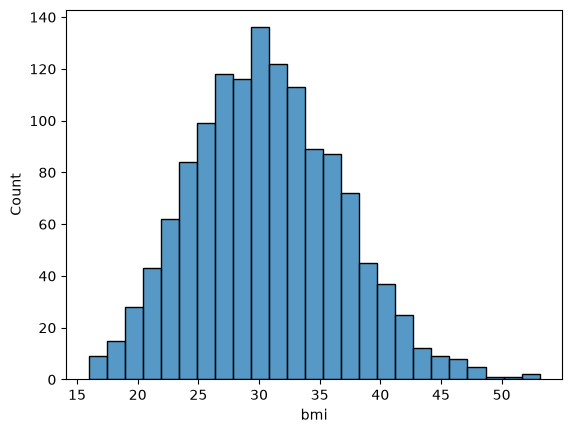

In [149]:
sns.histplot(df['bmi'])

In [150]:
cleaned_df['bmi_category']=pd.cut(
    cleaned_df['bmi'],
    bins=[0, 18.5, 24.9, 29.9, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)
cleaned_df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,1,16884.92400,False,False,True,Overweight
1,18,0,33.770,1,0,1725.55230,False,True,False,Obese
2,28,0,33.000,3,0,4449.46200,False,True,False,Obese
3,33,0,22.705,0,0,21984.47061,True,False,False,Normal
4,32,0,28.880,0,0,3866.85520,True,False,False,Overweight


In [151]:
cleaned_df=pd.get_dummies(cleaned_df,columns=['bmi_category'],drop_first=True)
cleaned_df.head().astype(int)


,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,1,0,1,0
1,18,0,33,1,0,1725,0,1,0,0,0,1
2,28,0,33,3,0,4449,0,1,0,0,0,1
3,33,0,22,0,0,21984,1,0,0,1,0,0
4,32,0,28,0,0,3866,1,0,0,0,1,0


# FEATURE SCALING 

In [152]:
from sklearn.preprocessing import StandardScaler
cols=['age','bmi','children']
scaler = StandardScaler()
cleaned_df[cols]=scaler.fit_transform(cleaned_df[cols])
 

In [153]:
cleaned_df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,False,False,True,False,True,False
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,False,True,False,False,False,True
2,-0.799350,0,0.383155,1.580143,0,4449.46200,False,True,False,False,False,True
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,True,False,False,True,False,False
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,True,False,False,False,True,False


# FEATURE SELECTION

In [156]:
from scipy.stats import pearsonr
selected_features = ['age', 'bmi', 'children', 'is_female', 'is_smoker', 
                     'region_northwest', 'region_southeast', 'region_southwest', 
                     'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese']

correlations = {
    feature: pearsonr(cleaned_df[feature], cleaned_df['charges'])[0] 
    for feature in selected_features
}
correlations_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'pearson_Correlation'])
correlations_df.sort_values(by='pearson_Correlation', ascending=False, inplace=True)

In [157]:
correlations_df

,Feature,pearson_Correlation
4,is_smoker,0.787234
0,age,0.298308
1,bmi,0.198401
10,bmi_category_Obese,0.197659
6,region_southeast,0.073578
2,children,0.067389
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058044
8,bmi_category_Normal,-0.105655


In [159]:
cat_features = ['is_female', 'is_smoker', 'region_northwest', 'region_southeast',
                 'region_southwest','bmi_category_Normal', 'bmi_category_Overweight',
                   'bmi_category_Obese']

In [161]:
from scipy.stats import chi2_contingency
import pandas as pd 
alpha = 0.05
cleaned_df['charges_bin'] = pd.qcut(cleaned_df['charges'],q=4, labels=False)
chi2_results = {}
   
for col in cat_features:
    contingency = pd.crosstab(cleaned_df[col], cleaned_df['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = "Reject H0 (keep feature)" if p_val < alpha else "Fail to Reject H0 (drop feature)"
    chi2_results[col] = {'chi2_statistic': chi2_stat, 'p_value': p_val, 'decision': decision}

chi2_df = pd.DataFrame(chi2_results).T
chi2_df.sort_values(by='p_value')


,chi2_statistic,p_value,decision
is_smoker,848.219178,0.0,Reject H0 (keep feature)
region_southeast,15.998167,0.001135,Reject H0 (keep feature)
is_female,10.258784,0.01649,Reject H0 (keep feature)
bmi_category_Obese,7.654464,0.05372,Fail to Reject H0 (drop feature)
region_southwest,5.091893,0.165191,Fail to Reject H0 (drop feature)
bmi_category_Normal,4.263673,0.234364,Fail to Reject H0 (drop feature)
bmi_category_Overweight,4.201575,0.240504,Fail to Reject H0 (drop feature)
region_northwest,1.13424,0.768815,Fail to Reject H0 (drop feature)


In [169]:
final_df=cleaned_df[['age','children','bmi','charges','is_smoker','region_southeast','is_female','bmi_category_Obese']]
final_df[['region_southeast','bmi_category_Obese']].astype(int)


,region_southeast,bmi_category_Obese
0,0,0
1,1,1
2,1,1
3,0,0
4,0,0
...,...,...
1333,0,1
1334,0,1
1335,1,1
1336,0,0


In [170]:
final_df

,age,children,bmi,charges,is_smoker,region_southeast,is_female,bmi_category_Obese
0,-1.440418,-0.909234,-0.453160,16884.92400,1,False,1,False
1,-1.511647,-0.079442,0.509422,1725.55230,0,True,0,True
2,-0.799350,1.580143,0.383155,4449.46200,0,True,0,True
3,-0.443201,-0.909234,-1.305052,21984.47061,0,False,0,False
4,-0.514431,-0.909234,-0.292456,3866.85520,0,False,0,False
...,...,...,...,...,...,...,...,...
1333,0.767704,1.580143,0.050269,10600.54830,0,False,0,True
1334,-1.511647,-0.909234,0.206053,2205.98080,0,False,1,True
1335,-1.511647,-0.909234,1.014490,1629.83350,0,True,1,True
1336,-1.297958,-0.909234,-0.797524,2007.94500,0,False,1,False
